Images: 4400
Labels: {'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}


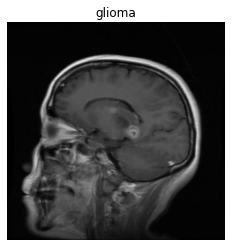

In [21]:
import torch
import matplotlib.pyplot as plt
import torch.nn as nn
from torch.utils.data import DataLoader, random_split
import random
from torchvision import datasets, transforms
import torch.optim as optim

## Scales the images to 256x256 pixels and convert them to a tensor of pixels with values in [0,1]
transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor()
])

## Gathers the training and testing data images from the folder
training_data = datasets.ImageFolder(
    root="brainmris/Training",
    transform=transform
)
test_data = datasets.ImageFolder(
    root="brainmris/Testing",
    transform=transform
)

## Splits the training and validation data into sets of sizes 4,400 and 1,200
train_data, val_data = random_split(
    training_data,
    [4400, 1200],
    generator=torch.Generator().manual_seed(42)
)

## Loads the training, validation and test data
training_loader = DataLoader(
    train_data,
    batch_size=64,
    shuffle=True
)
validation_loader = DataLoader(
    val_data,
    batch_size=128,
    shuffle=False
)
test_loader = DataLoader(
    test_data,
    batch_size=2000,
    shuffle=True
)



print("Images:", len(train_data))
print("Labels:", training_data.class_to_idx)
image, label = val_data[4]

plt.imshow(image.permute(1, 2, 0))  # [channels, height, width] → [height, width, channels]
plt.title(training_data.classes[label])
plt.axis("off")
plt.show()

## Architecture design

Worked with GenAI to design an architecture for the model. I asked it to not give any code or hints, but ask questions that required me to work out the features. The following architecture was designed in collaboration with GenAI but through my own reasoning. Given that this is my first real CNN project, I decided that this would be a worthwhile time to use GenAI for development. As such, the architecture that will be implemented is as follows:

<figure style="text-align: center;">
  <img src=brainmricnn.png alt="Brain MRI CNN architecture" width="1000">
  <figcaption>Figure 1: Brain MRI CNN architecture. Figured developed by OpenAI.</figcaption>
</figure>

ADD IN PURPOSE OF THIS CNN


Validation accuracy: 72.25%
Epoch 1: training loss = 0.9820, validation loss = 0.7395
Validation accuracy: 72.67%
Epoch 2: training loss = 0.6105, validation loss = 0.6418
Validation accuracy: 75.08%
Epoch 3: training loss = 0.5089, validation loss = 0.5777
Validation accuracy: 83.83%
Epoch 4: training loss = 0.4429, validation loss = 0.4784
Validation accuracy: 83.83%
Epoch 5: training loss = 0.3819, validation loss = 0.4703
Validation accuracy: 85.00%
Epoch 6: training loss = 0.3311, validation loss = 0.4066
Validation accuracy: 84.25%
Epoch 7: training loss = 0.3007, validation loss = 0.4270
Validation accuracy: 87.17%
Epoch 8: training loss = 0.2827, validation loss = 0.3801
Validation accuracy: 87.92%
Epoch 9: training loss = 0.2541, validation loss = 0.3868
Validation accuracy: 89.50%
Epoch 10: training loss = 0.2121, validation loss = 0.3434
Validation accuracy: 89.08%
Epoch 11: training loss = 0.1888, validation loss = 0.3390
Validation accuracy: 88.58%
Epoch 12: training loss 

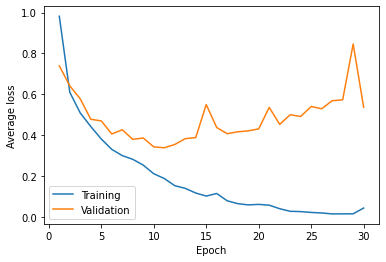

In [22]:
torch.manual_seed(0)

class MRINet(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Conv2d(in_channels=1, out_channels=6, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Conv2d(in_channels=6, out_channels=8, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Conv2d(in_channels=8, out_channels=10, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Flatten(),
#             nn.Dropout(p=0.3),
            nn.Linear(10*32*32, 4)
        )
    def forward(self, x):
        return self.network(x)

model = MRINet()
criterion = nn.CrossEntropyLoss()
optimiser = optim.Adam(model.parameters(), lr=1e-3)

tloss = []
vloss = []

## Training model
for epoch in range(30):
    model.train()
    train_loss = 0.0
    train_count = 0
    
    for images, labels in training_loader:
        optimiser.zero_grad()
        predictions = model(images[:, 0:1, :, :])  ## selects the first grayscale image (they are identical)
        loss = criterion(predictions, labels)
        loss.backward()
        optimiser.step()
        
        batch_size = labels.size(0)
        train_loss += loss.item() * batch_size
        train_count += batch_size
        
    tloss.append(train_loss / train_count)
    
    # Checks on validation set after each epoch. Will allow us to compare training curve and validation curve
    model.eval()
    val_loss = 0.0
    val_count = 0
    
    with torch.no_grad():
        val_correct = 0
        for vimages, vlabels in validation_loader:
            vpredict = model(vimages[:, 0:1, :, :])
            val_correct += (vpredict.argmax(dim=1) == vlabels).sum().item()
            loss = criterion(vpredict, vlabels)

            batch_size = vlabels.size(0)
            val_loss += loss.item() * batch_size
            val_count += batch_size

    vloss.append(val_loss / val_count)
    print(f"Validation accuracy: {100 * val_correct / val_count:.2f}%")
    
    print(
        f"Epoch {epoch + 1}: "
        f"training loss = {tloss[-1]:.4f}, "
        f"validation loss = {vloss[-1]:.4f}"
    )

epochs = range(1, len(tloss) + 1)
plt.plot(epochs, tloss, label="Training")
plt.plot(epochs, vloss, label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Average loss")
plt.legend()
plt.show()


In [23]:
total=0
correct=0

model.eval()
with torch.no_grad():
    for timages, tlabels in test_loader:
        tpredict = model(timages[:, 0:1, :, :])
        predicted = torch.argmax(tpredict, dim=1)
        total += tlabels.size(0)
        correct += (predicted == tlabels).sum().item()
        
print(f"Test accuracy: + {correct / total:.4f}")

Test accuracy: + 0.8413


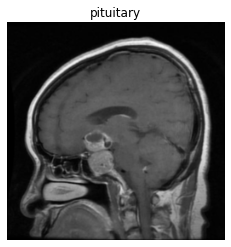

In [7]:
image, label = training_data[3999]

plt.imshow(image.permute(1, 2, 0))  # [channels, height, width] → [height, width, channels]
plt.title(training_data.classes[label])
plt.axis("off")
plt.show()